# 1 – Exploración y Análisis Descriptivo (EDA)

**Proyecto Final – Aprendizaje Automático | Comillas 2025/2026**

En este notebook hacemos un análisis exploratorio del dataset sobre abandono, permanencia y éxito académico de estudiantes de educación superior.

El objetivo es entender la distribución de las variables, detectar valores nulos o atípicos, y sacar primeras conclusiones sobre qué factores pueden estar relacionados con la trayectoria del alumnado.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [ ]:

# Configuración de gráficos
plt.rcParams['figure.figsize'] = (10, 5)

os.makedirs('plots', exist_ok=True)

# Cargamos el dataset
df = pd.read_csv('rendimiento_estudiantes.csv', sep=';')
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()


Dimensiones: 4424 filas x 37 columnas


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


## 1.1 Información general del dataset

In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   estado_civil                       4424 non-null   object 
 1   modo_solicitud                     4424 non-null   object 
 2   orden_solicitud                    4424 non-null   int64  
 3   curso                              4424 non-null   object 
 4   asistencia_diurna_vespertina       4424 non-null   object 
 5   cualificacion_previa               4424 non-null   object 
 6   nota_cualificacion_previa          4424 non-null   float64
 7   nacionalidad                       4424 non-null   object 
 8   cualificacion_madre                4424 non-null   object 
 9   cualificacion_padre                4424 non-null   object 
 10  ocupacion_madre                    4424 non-null   object 
 11  ocupacion_padre                    4424 non-null   objec

In [11]:
df.describe(include='all')
# Estudio del df de todas las variables

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
count,4424,4424,4424.000000,4424,4424,4424,4424.000000,4424,4424,4424,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424
unique,6,18,NaN,17,2,17,NaN,21,29,34,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,soltero/a,1a_fase_contingente_general,NaN,enfermeria,diurna,educacion_secundaria,NaN,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,graduado
freq,3919,1708,NaN,766,3941,3717,NaN,4314,1069,1209,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2209
mean,NaN,NaN,1.727848,NaN,NaN,NaN,132.613314,NaN,NaN,NaN,...,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969,NaN
std,NaN,NaN,1.313793,NaN,NaN,NaN,13.188332,NaN,NaN,NaN,...,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935,NaN
min,NaN,NaN,0.000000,NaN,NaN,NaN,95.000000,NaN,NaN,NaN,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,NaN
25%,NaN,NaN,1.000000,NaN,NaN,NaN,125.000000,NaN,NaN,NaN,...,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000,NaN
50%,NaN,NaN,1.000000,NaN,NaN,NaN,133.100000,NaN,NaN,NaN,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,NaN
75%,NaN,NaN,2.000000,NaN,NaN,NaN,140.000000,NaN,NaN,NaN,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,NaN


In [12]:
# Revisamos la variable objetivo
print("Distribución de la variable objetivo:")
print(df['objetivo'].value_counts())

print(f"\nEn porcentaje:")
print(df['objetivo'].value_counts(normalize=True).round(4) * 100)

Distribución de la variable objetivo:
objetivo
graduado       2209
abandono       1421
matriculado     794
Name: count, dtype: int64

En porcentaje:
objetivo
graduado       49.93
abandono       32.12
matriculado    17.95
Name: proportion, dtype: float64


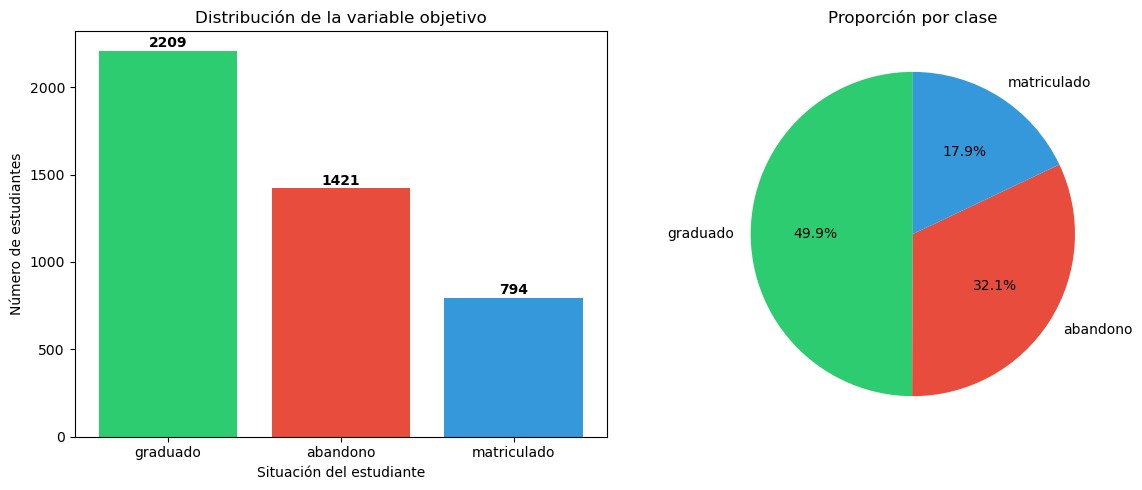

Las clases están algo desbalanceadas: hay más Graduados, casi 50%, que Abandonos y Matriculados.


In [13]:
# Visualizamos la distribución de la variable objetivo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colores = ['#2ecc71','#e74c3c', '#3498db']
conteos = df['objetivo'].value_counts()
# Histograma
axes[0].bar(conteos.index, conteos.values, color=colores)
axes[0].set_title('Distribución de la variable objetivo')
axes[0].set_xlabel('Situación del estudiante')
axes[0].set_ylabel('Número de estudiantes')
for i, v in enumerate(conteos.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')
# Diagrama de tarta
axes[1].pie(conteos.values, labels=conteos.index, autopct='%1.1f%%',colors=colores, startangle=90)
axes[1].set_title('Proporción por clase')

plt.tight_layout()
plt.savefig('plots/distribucion_objetivo.png', dpi=150, bbox_inches='tight')
plt.show()
print("Las clases están algo desbalanceadas: hay más Graduados, casi 50%, que Abandonos y Matriculados.")


Rojo = abandono, azul = matriculado, verde = graduado

## 1.2 Valores nulos y tipos de variables

In [14]:
# Comprobamos valores nulos
nulos = df.isnull().sum()
print("Columnas con valores nulos:")
print(nulos[nulos > 0])
print("No hay valores nulos en el dataset")

Columnas con valores nulos:
Series([], dtype: int64)
No hay valores nulos en el dataset


In [15]:
# Separamos variables no objetivo en numéricas y categóricas
cols_num = df.select_dtypes(include='number').columns.tolist()
cols_cat = df.select_dtypes(include='object').columns.tolist()
cols_cat.remove('objetivo')
print(f"Variables numéricas ({len(cols_num)}): {cols_num}")
print(f"\nVariables categóricas ({len(cols_cat)}): {cols_cat}")


Variables numéricas (19): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']

Variables categóricas (17): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 1.3 Análisis de variables numéricas

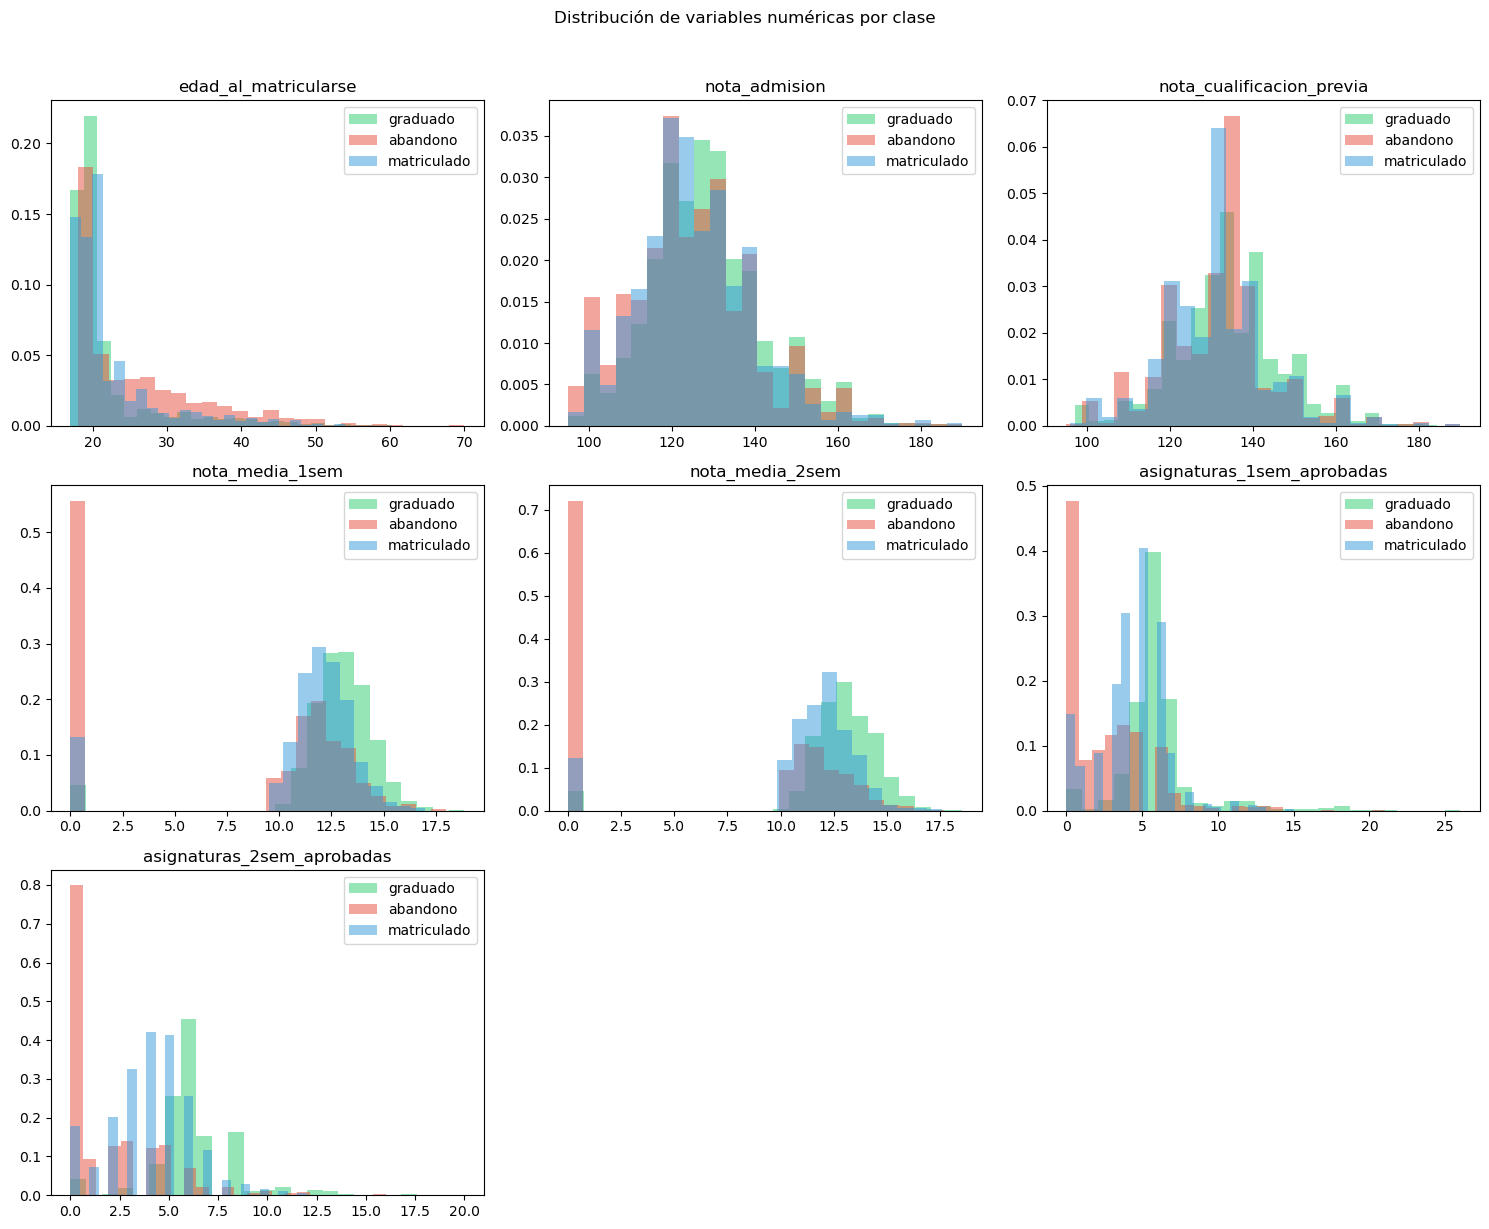

In [16]:
# Distribuciones de variables numéricas más relevantes para graduar, matricular o abandonar
vars_interes = ['edad_al_matricularse', 'nota_admision', 'nota_cualificacion_previa','nota_media_1sem', 
                'nota_media_2sem','asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(vars_interes):
    for clase, color in zip(['graduado','abandono', 'matriculado' ],colores):
        subset = df[df['objetivo'] == clase][col]
        axes[i].hist(subset, bins=25, alpha=0.5, label=clase, color=color, density=True)
    axes[i].set_title(col)
    axes[i].legend()

# Ocultamos los vacios
axes[-1].set_visible(False)
axes[-2].set_visible(False)

plt.suptitle('Distribución de variables numéricas por clase', y=1.02)
plt.tight_layout()
plt.savefig('plots/distribuciones_numericas.png', dpi=150, bbox_inches='tight')
plt.show()

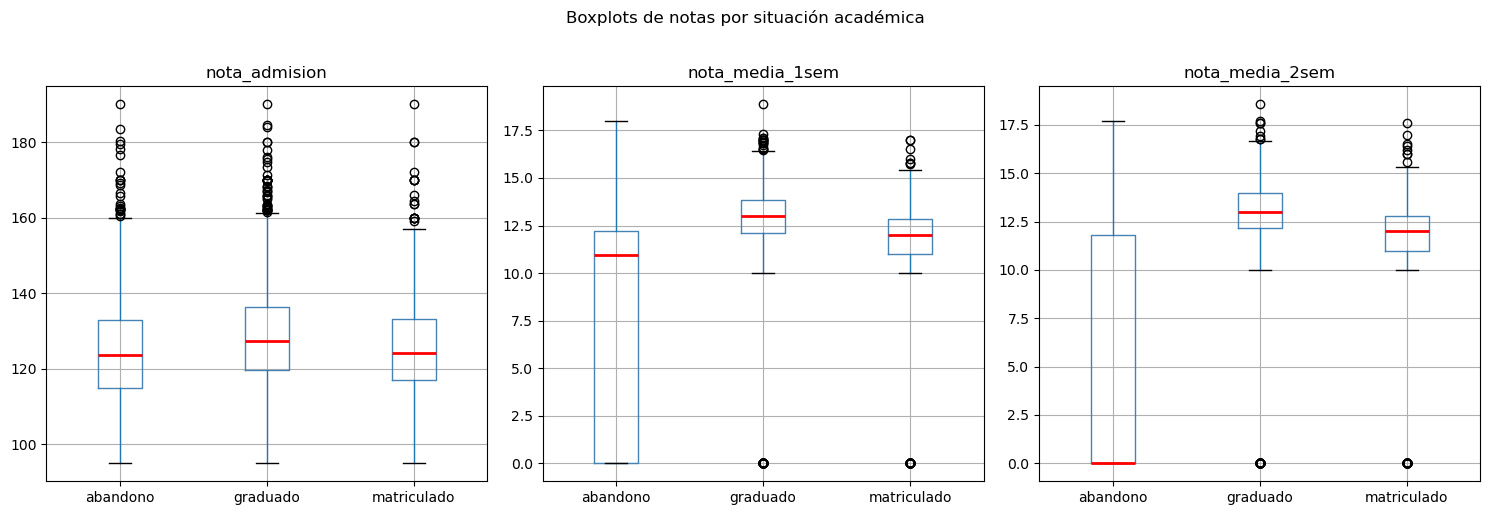

In [17]:
# Boxplots de notas por clase
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
notas = ['nota_admision', 'nota_media_1sem', 'nota_media_2sem']

for ax, nota in zip(axes, notas):
    df.boxplot(column=nota, by='objetivo', ax=ax, boxprops=dict(color='steelblue'),medianprops=dict(color='red', linewidth=2))
    ax.set_title(nota)
    ax.set_xlabel('')

plt.suptitle('Boxplots de notas por situación académica', y=1.02)
plt.tight_layout()
plt.savefig('plots/boxplots_notas.png', dpi=150, bbox_inches='tight')
plt.show()


Aunque en las notas de admisión no se diferencian mucho, está claro que en el resto los matriculados y sobretodo los graduados tienen mejores notas medias que los que abandonan. 
Aún así, se ven outliers interesantes en los que abandonan, con el bigote superior alcanzando notas mejores que las de los otros.
Observemos los outliers para todas las variables numéricas


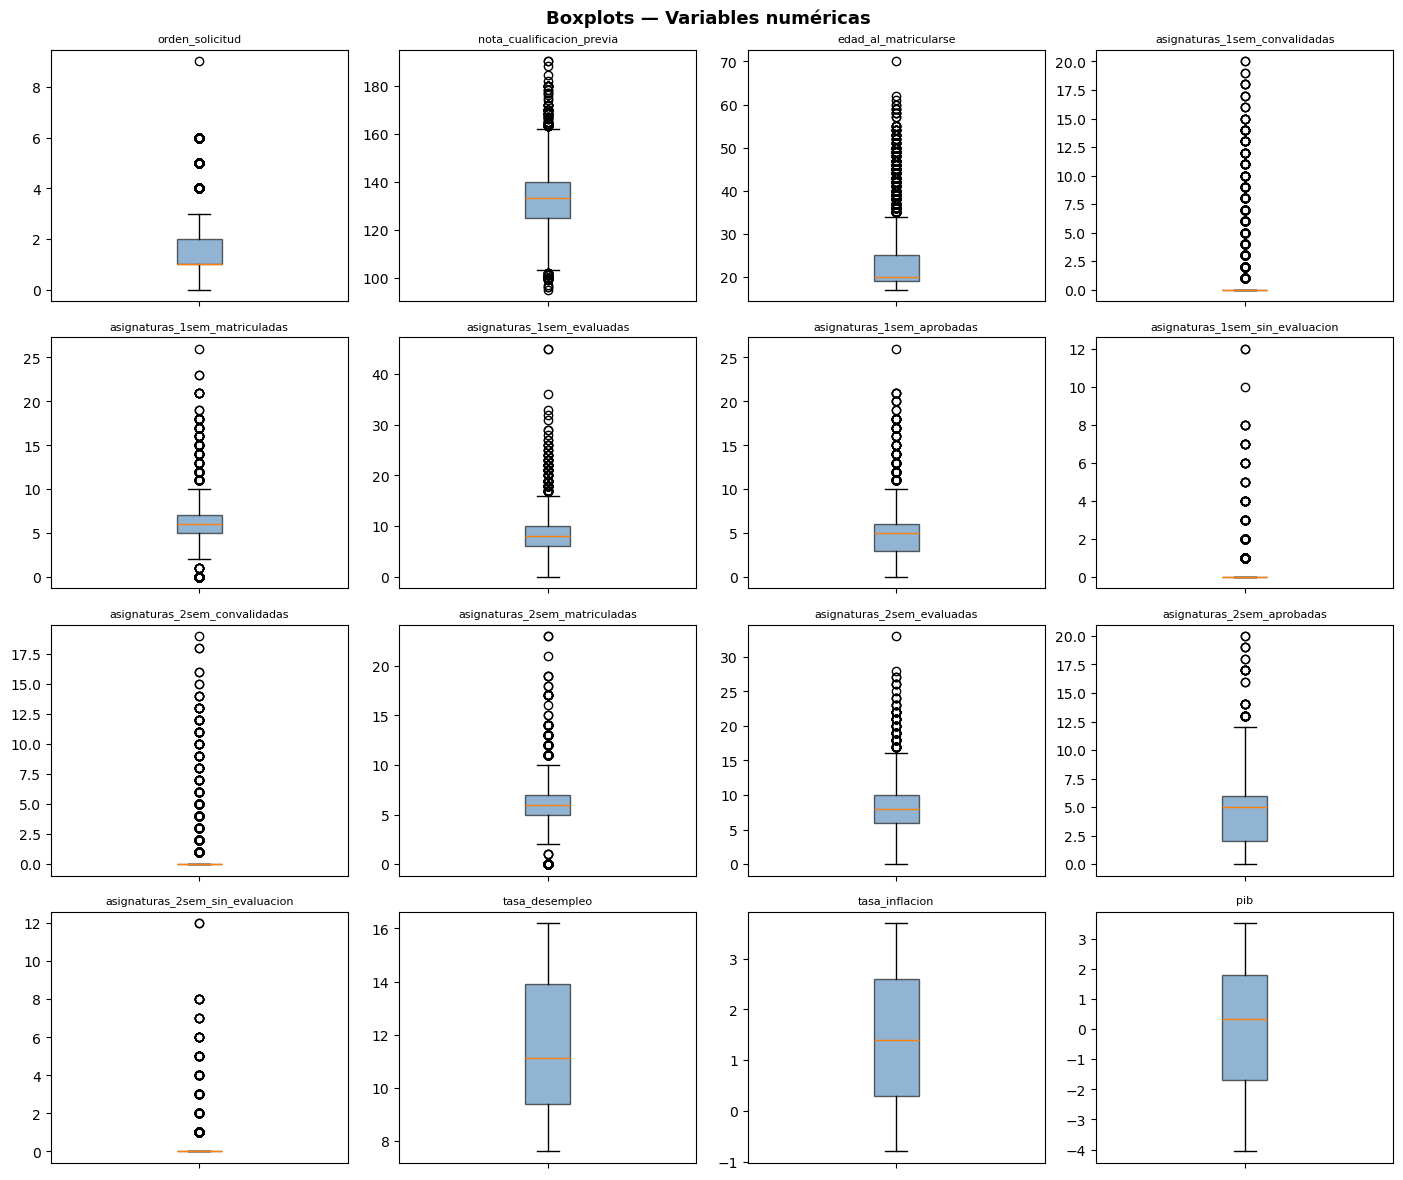

In [18]:
n_num = len(cols_num)-3
n_cols_plot = 4
n_rows_plot = int(np.ceil(n_num / n_cols_plot))

fig, axes = plt.subplots(n_rows_plot, n_cols_plot,figsize=(n_cols_plot * 3.5, n_rows_plot * 3))
axes = axes.flatten()
# Excluimos las variables de nota y asignaturas, que ya hemos analizado
cols_num1 = [col for col in cols_num if col not in ['nota_admision', 'nota_media_1sem', 'nota_media_2sem']]
for i, col in enumerate(cols_num1):
    axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,boxprops=dict(facecolor='steelblue', alpha=0.6))
    axes[i].set_title(col, fontsize=8)
    axes[i].tick_params(axis='x', labelbottom=False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots — Variables numéricas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [19]:
def iqr_outlier_summary(df, cols):
    records = []
    for col in cols:
        Q1, Q3 = df[col].quantile([0.25, 0.75])
        IQR = Q3 - Q1
        min, max = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
        n_out = ((df[col] < min) | (df[col] > max)).sum()
        records.append({'variable': col, 'lim_inf': round(min, 3),'lim_sup': round(max, 3),
                        'n_outliers': n_out,'porcentaje_outliers': round(n_out / len(df) * 100, 2), 'skewness': df[col].skew()})
    return pd.DataFrame(records).query('n_outliers > 0').sort_values('porcentaje_outliers', ascending=False)

outlier_summary = iqr_outlier_summary(df, cols_num)
print(f'Variables con outliers IQR: {len(outlier_summary)}')
outlier_summary

Variables con outliers IQR: 16


,variable,lim_inf,lim_sup,n_outliers,porcentaje_outliers,skewness
14,nota_media_2sem,6.875,17.208,877,19.82,-1.313650
8,nota_media_1sem,7.400,17.000,726,16.41,-1.568146
4,asignaturas_1sem_convalidadas,0.000,0.000,577,13.04,4.169049
0,orden_solicitud,-0.500,3.500,541,12.23,1.881050
10,asignaturas_2sem_convalidadas,0.000,0.000,530,11.98,4.634820
3,edad_al_matricularse,10.000,34.000,441,9.97,2.054988
5,asignaturas_1sem_matriculadas,2.000,10.000,424,9.58,1.619041
11,asignaturas_2sem_matriculadas,2.000,10.000,369,8.34,0.788114
9,asignaturas_1sem_sin_evaluacion,0.000,0.000,294,6.65,8.207403
15,asignaturas_2sem_sin_evaluacion,0.000,0.000,282,6.37,7.267701


Tenemos outliers relevantes, nos dan información, no deberíamos eliminarlos pues nos arriesgasmos a perder información verdaderamente importante para los abandonos

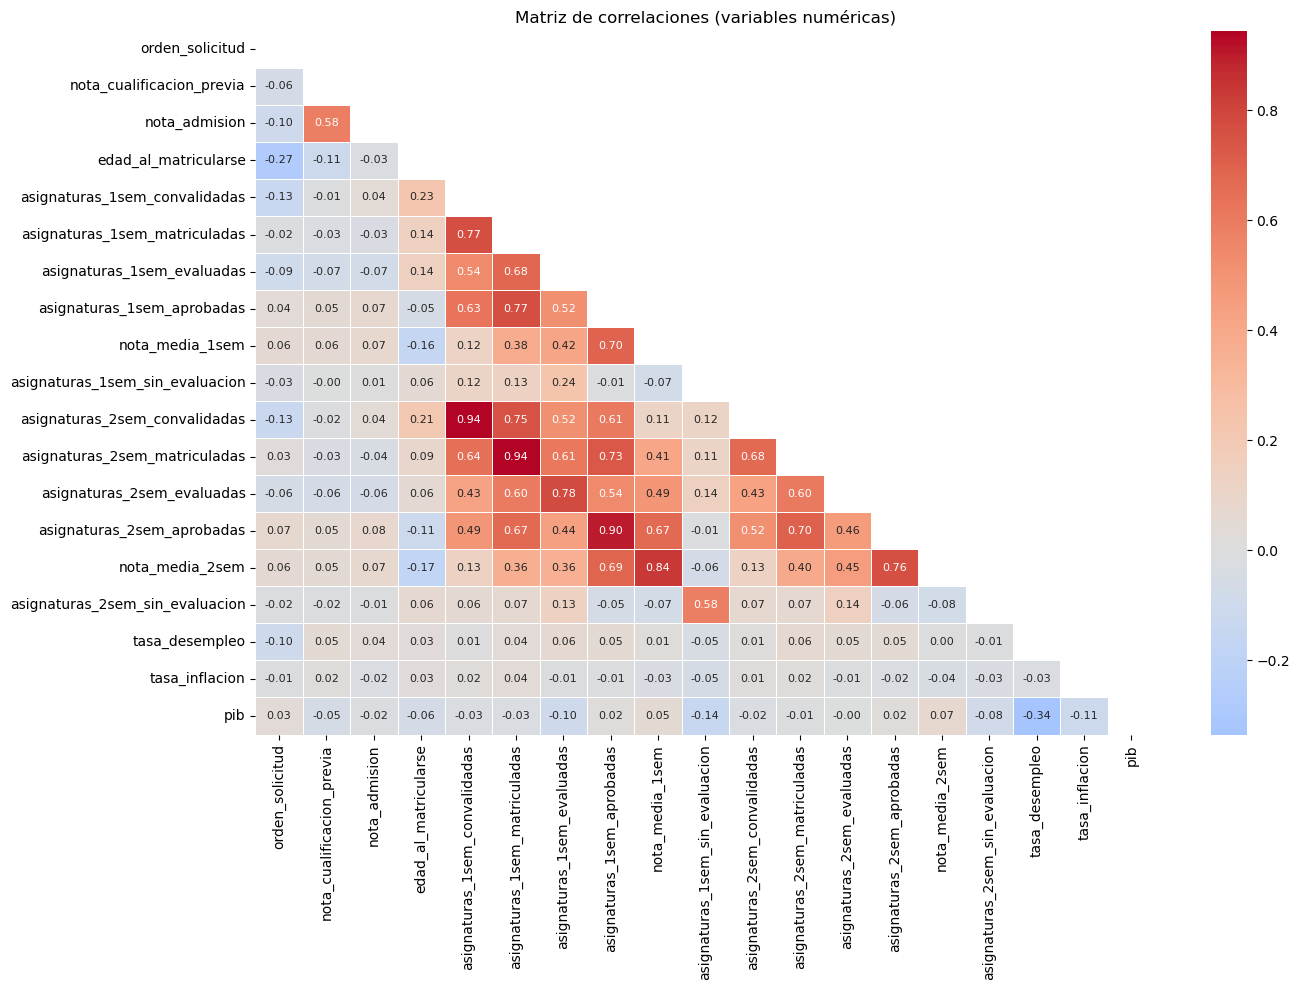

In [20]:
# Correlación entre variables numéricas
plt.figure(figsize=(14, 10))
corr = df[cols_num].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # Mascara para solo ver mitad
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('Matriz de correlaciones (variables numéricas)')
plt.tight_layout()
plt.savefig('plots/correlaciones.png', dpi=150, bbox_inches='tight')
plt.show()



Las variables de rendimiento del 1er y 2do semestre están muy correlacionadas entre sí, lo que tiene sentido: el que aprueba muchas en el 1er semestre suele hacerlo en el 2do también.
También, se correlacionan positivamente, como es obvio, las variables de asignaturas aprobadas y nota media: el que aprueba más tendrá mejor nota media (por lo general)
Pocas de estas variables tienen una correalacion negativa significativa, la que más siendo la tasa de desempleo con el pib, lo que es lógioc

## 1.4 Análisis de variables categóricas

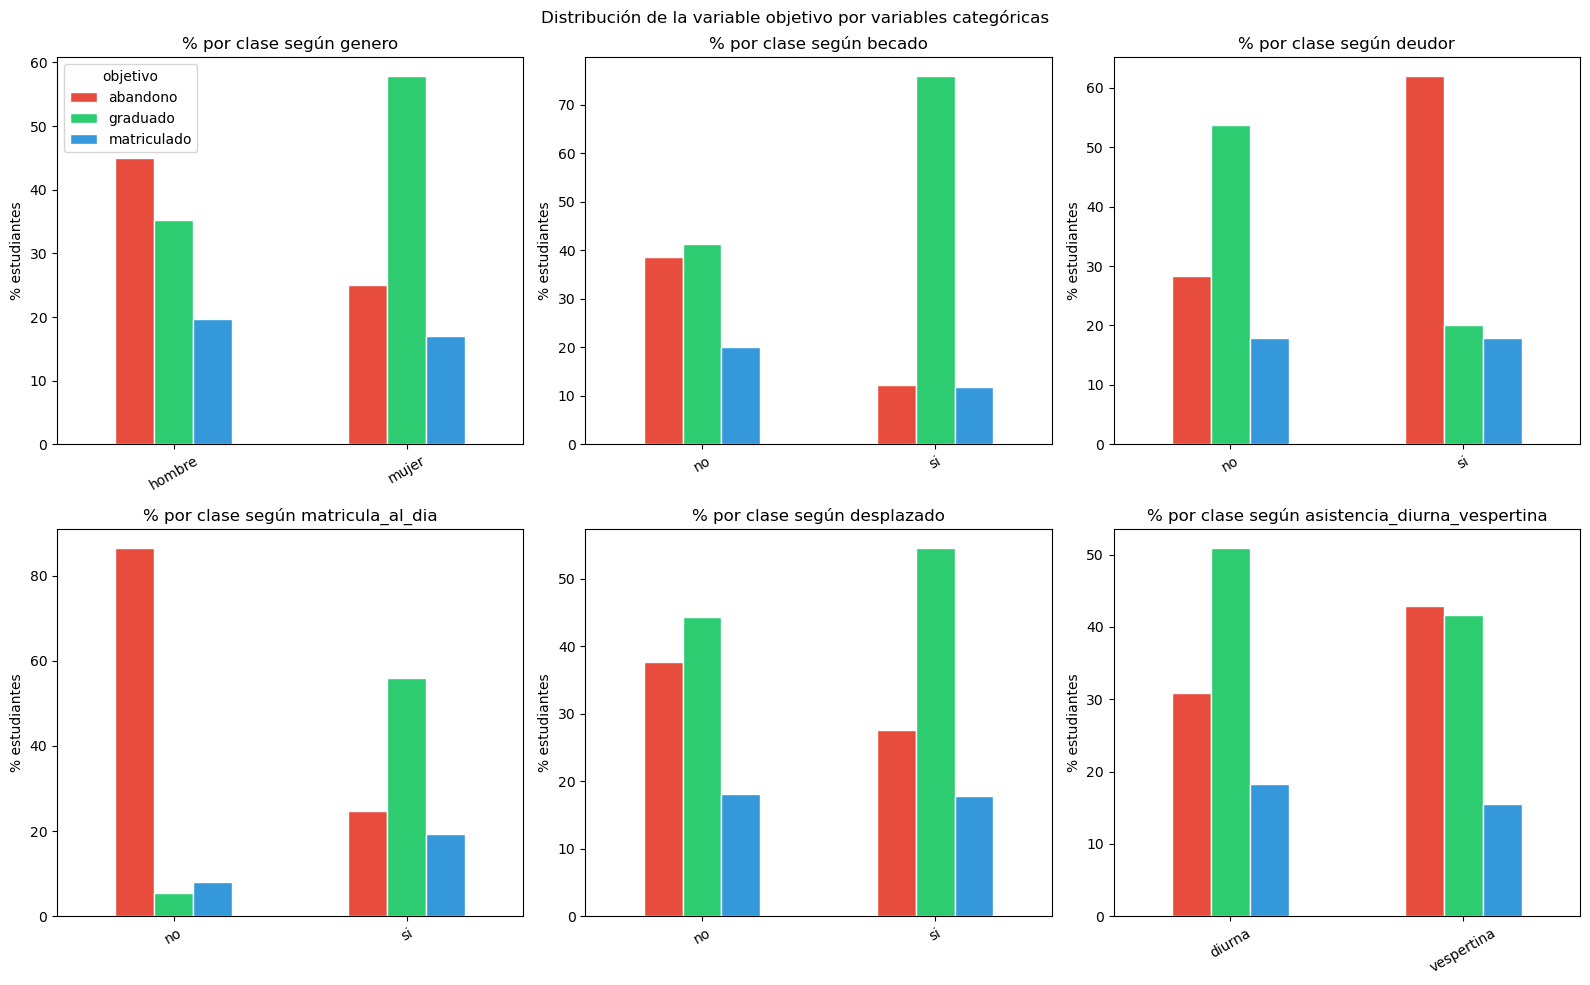

In [21]:
# Distribución de algunas variables categóricas importantes
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
vars_cat = ['genero', 'becado', 'deudor', 'matricula_al_dia',
            'desplazado', 'asistencia_diurna_vespertina']

for ax, col in zip(axes.flatten(), vars_cat):
    tabla = df.groupby([col, 'objetivo']).size().unstack(fill_value=0)
    tabla_pct = tabla.div(tabla.sum(axis=1), axis=0) * 100
    tabla_pct.plot(kind='bar', ax=ax, color=['#e74c3c','#2ecc71', '#3498db'], edgecolor='white', legend=(col == vars_cat[0]))
    ax.set_title(f'% por clase según {col}')
    ax.set_xlabel('')
    ax.set_ylabel('% estudiantes')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Distribución de la variable objetivo por variables categóricas')
plt.tight_layout()
plt.savefig('plots/categoricas_vs_objetivo.png', dpi=150, bbox_inches='tight')
plt.show()


In [22]:
# Análisis de becados vs objetivo
print("Tasa según si tiene beca:")
tabla_beca = df.groupby(['becado', 'objetivo']).size().unstack(fill_value=0)
tabla_beca_pct = tabla_beca.div(tabla_beca.sum(axis=1), axis=0).round(3) * 100
print(tabla_beca_pct)

print(f"\nTasa según si está al día con la matrícula:")
tabla_matricula = df.groupby(['matricula_al_dia', 'objetivo']).size().unstack(fill_value=0)
tabla_matricula_pct = tabla_matricula.div(tabla_matricula.sum(axis=1), axis=0).round(3) * 100
print(tabla_matricula_pct)

print(f"\nTasa según asistencia diurna o vespertina:")
tabla_diurna = df.groupby(['asistencia_diurna_vespertina', 'objetivo']).size().unstack(fill_value=0)
tabla_diurna_pct = tabla_diurna.div(tabla_diurna.sum(axis=1), axis=0).round(3) * 100
print(tabla_diurna_pct)

Tasa según si tiene beca:
objetivo  abandono  graduado  matriculado
becado                                   
no            38.7      41.3         20.0
si            12.2      76.0         11.8

Tasa según si está al día con la matrícula:
objetivo          abandono  graduado  matriculado
matricula_al_dia                                 
no                    86.6       5.5          8.0
si                    24.7      56.0         19.3

Tasa según asistencia diurna o vespertina:
objetivo                      abandono  graduado  matriculado
asistencia_diurna_vespertina                                 
diurna                            30.8      51.0         18.2
vespertina                        42.9      41.6         15.5


Con esto, se observa que hay tener beca aumenta el número de graduados y, principalmente, reduce el número de abandono.
No estar al día está muy relacionado con el abandono, con la mayoría de los que no estánal día abandonando.
Tener asistencia diurna parece reducir el porcentaje de abandono y aumentar el de graduado, con el de matriculado manteniendose igual.

## 1.5 Variables macroeconómicas

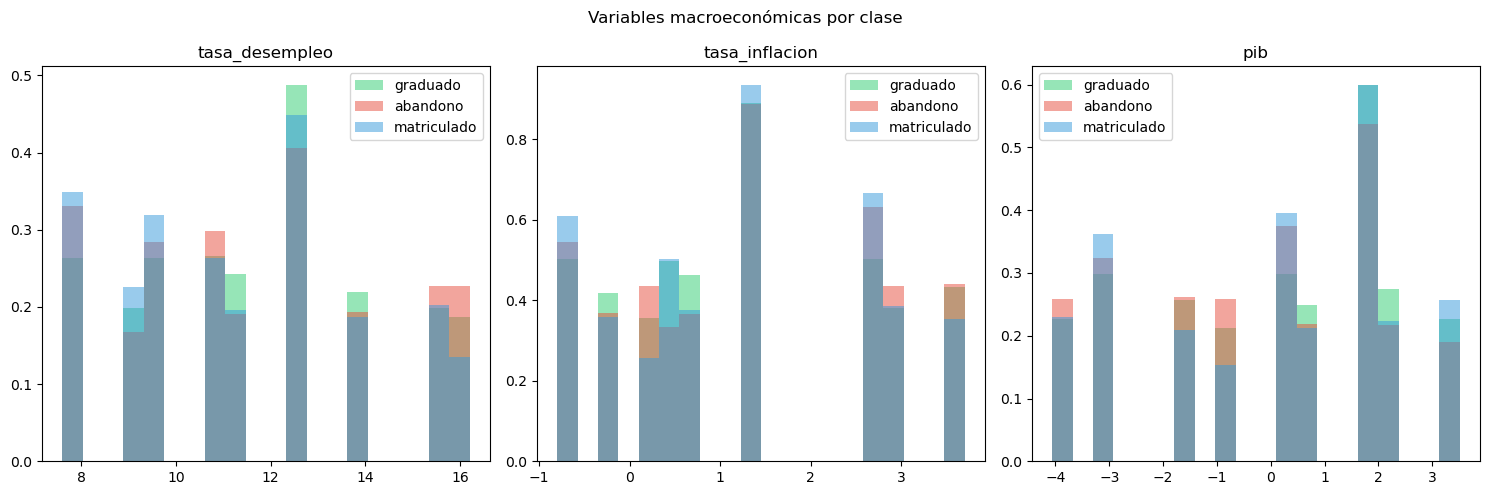

In [23]:
# Vemos si las variables macro economicas tienen relación con el objetivo
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
macro_vars = ['tasa_desempleo', 'tasa_inflacion', 'pib']

for ax, var in zip(axes, macro_vars):
    for clase, color in zip(['graduado','abandono', 'matriculado'],colores):
        subset = df[df['objetivo'] == clase][var]
        ax.hist(subset, bins=20, alpha=0.5, label=clase, color=color, density=True)
    ax.set_title(var)
    ax.legend()

plt.suptitle('Variables macroeconómicas por clase')
plt.tight_layout()
plt.savefig('plots/macroeconomicas.png', dpi=150, bbox_inches='tight')
plt.show()


Las variables macroeconómicas no parecen distinguir bien las clases. Parecen tener un impacto menor que el rendimiento académico.

## 1.6 Conclusiones del EDA

- El dataset tiene **4.424 estudiantes** sin valores nulos, lo que simplifica el preprocesado.
- La variable objetivo está **desbalanceada**: ~49% Graduados, ~33% Abandonos, ~18% Matriculados.
- Las variables más discriminantes son las de **rendimiento semestral** (notas, asignaturas aprobadas): los graduados tienen notablemente mejores resultados.
- Variables socioeconómicas como `matricula_al_dia`, `becado` y `deudor` también muestran diferencias entre clases.
- Las variables macroeconómicas apenas discriminan, aunque las incluiremos inicialmente.
- Hay que tener **cuidado con las variables del 2º semestre** en la tarea de regresión para evitar fuga de información.
